# Сравнение сетей Петри четырёх групп компьютеров

Цель - проверить, насколько сети одной группы описывают журналы других. Только **Microsoft-Windows-Kernel-Power** (как в ноутбуке 04), `Kernel-Power:41` применяется для разметки отказов, но не входит в трассы.

Группы: прежние компьютеры и три группы школьных машин.

## 1. Данные и параметры

Порог фильтрации совпадает с прежними экспериментами: не менее 20 сессий и 50 событий компоненты на машину.

`SPLIT_MODE`: 
- `random` —  случайное разбиение
- `stratified` — разбиение со стратификацией по времени. 
Для обычной стратификации `STRATIFIED_CANDIDATES = 1`, то есть выполняем
стратифицированное разбиение только один раз, без дополнительного подбора

1. Рассчитываем длительность каждой сессии как разность между
   временем последнего и первого зарегистрированных событий.

2. Для каждого компьютера вычисляем медианную длительность его сессий.

3. Внутри каждой группы разделяем компьютеры на страты
   по квантилям медианной длительности (до четырёх).

4. Выполняем разбиение компьютеров на Train и Test (75/25)
   с помощью `train_test_split` с параметром `stratify`.

5. В зависимости от значения `STRATIFIED_CANDIDATES`
   используем один из двух вариантов:

   - `STRATIFIED_CANDIDATES = 1` — обычная стратификация. Выполняем разбиение один раз с `random_state = 42`.

   - `STRATIFIED_CANDIDATES = 100` — стратификация
     с доп подбором. Всего 100 разбиений
     с разными значениями `random_state` (от 42 до 141).
     Для каждого разбиения рассчитываем статистику Колмогорова — Смирнова (KS) и выбираем вариант с минимальным значением.

( Компьютеры в Train и Test не пересекаются)

компьютеры с близкими медианами могут иметь различные распределения длительности и различное количество сессий.

### Статистика Колмогорова — Смирнова (KS)

KS определяется как максимальное расстояние между двумя функциями распределения:

$$
D = \sup_{t \in \mathbb{R}}
|F_{\text{train}}(t) - F_{\text{test}}(t)|.
$$

Значения KS лежат в диапазоне от 0 до 1.
Чем меньше KS, тем ближе эмпирические распределения.
При KS = 0 эмпирические распределения совпадают.


In [2]:
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pm4py
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.cluster_comparison import (
    prepare_component_logs, split_by_machine, session_durations,
    stratify_machine_split,
)
from src.model_quality import _to_event_log
from src.models import transition_table

GROUPS = ["previous", "itplgn", "s-1547-3-410", "s-1547-3-413"]
MIN_SESSIONS = 20
MIN_EVENTS = 50
TEST_SHARE = 0.25
SEED = 42
SPLIT_MODE = "stratified"  # "random" — прежнее разбиение по машинам
STRATIFIED_CANDIDATES = 100
MAX_TEST_SESSIONS = 100   # None = все тестовые сессии
COMPUTE_PRECISION = True
MAX_PRECISION_SESSIONS = 40  # None = все выбранные тестовые сессии

log, sessions = prepare_component_logs()
session_times = session_durations(log, sessions)
stats, random_splits = split_by_machine(log, MIN_SESSIONS, MIN_EVENTS, TEST_SHARE, SEED)
if SPLIT_MODE == "stratified":
    stats, splits = stratify_machine_split(
        stats, session_times, TEST_SHARE, SEED, STRATIFIED_CANDIDATES)
elif SPLIT_MODE == "random":
    splits = random_splits
else:
    raise ValueError('SPLIT_MODE: "random" или "stratified"')
print("Режим разбиения:", SPLIT_MODE)
if set(splits) != set(GROUPS):
    raise ValueError(f"Ожидались группы {GROUPS}, обнаружены {list(splits)}")
display(stats.groupby("group").agg(
    machines=("machine_id", "count"),
    eligible=("eligible", "sum"),
    sessions=("sessions", "sum"),
    events=("events", "sum")
).reindex(GROUPS))
display(pd.DataFrame({g: {
    "train_machines": len(splits[g]["train"]),
    "test_machines": len(splits[g]["test"])
} for g in GROUPS}).T)
print("В построении моделей участвуют только train-машины.")
pm4py.util.constants.SHOW_PROGRESS_BAR = False



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




Школьные машины: 67, с нужными событиями: 67
itplgn: страт 4, KS = 0.037
previous: страт 3, KS = 0.086
s-1547-3-410: страт 4, KS = 0.019
s-1547-3-413: страт 4, KS = 0.032
Режим разбиения: stratified


,machines,eligible,sessions,events
group,,,,
previous,14,12,949,31496
itplgn,37,24,1528,25518
s-1547-3-410,15,14,2003,12803
s-1547-3-413,15,15,1533,7873


,train_machines,test_machines
previous,9,3
itplgn,18,6
s-1547-3-410,10,4
s-1547-3-413,11,4


В построении моделей участвуют только train-машины.


## 2. Обучающие и тестовые журналы

Для каждой группы строим сеть по части машин и проверяем её на оставшихся.

In [3]:
train_ids = {m for g in GROUPS for m in splits[g]["train"]}
test_ids = {m for g in GROUPS for m in splits[g]["test"]}
assert train_ids.isdisjoint(test_ids)

train = log[log["machine_id"].isin(train_ids)].copy()
test = log[log["machine_id"].isin(test_ids)].copy()

def sample_sessions(data, limit, seed):
    if limit is None or data["case_id"].nunique() <= limit:
        return data
    rng = np.random.default_rng(seed)
    pools = {m: list(rng.permutation(sorted(part["case_id"].unique())))
             for m, part in data.groupby("machine_id", sort=True)}
    selected = []
    while len(selected) < limit and any(pools.values()):
        for machine in sorted(pools):
            if pools[machine] and len(selected) < limit:
                selected.append(pools[machine].pop())
    return data[data["case_id"].isin(selected)]

test_logs = {g: sample_sessions(test[test["group"] == g], MAX_TEST_SESSIONS, SEED)
             for g in GROUPS}
display(pd.DataFrame({g: {
    "train_sessions": train.loc[train["group"] == g, "case_id"].nunique(),
    "test_sessions_total": test.loc[test["group"] == g, "case_id"].nunique(),
    "test_sessions_used": test_logs[g]["case_id"].nunique(),
    "test_FAIL": int((test_logs[g]["activity"] == "END_FAIL").sum())
} for g in GROUPS}).T)

,train_sessions,test_sessions_total,test_sessions_used,test_FAIL
previous,719,209,100,50
itplgn,922,438,100,69
s-1547-3-410,1403,584,100,59
s-1547-3-413,1095,438,100,40


## 2.1. Проверка разбиения по длительности сессий

Для выбранного разбиения строим общий KDE и KDE для каждой из групп. 

previous


,count,median,mean,share_over_100h
split,,,,
Test,209,2.05,18.36,2.39
Train,719,3.28,50.73,9.46


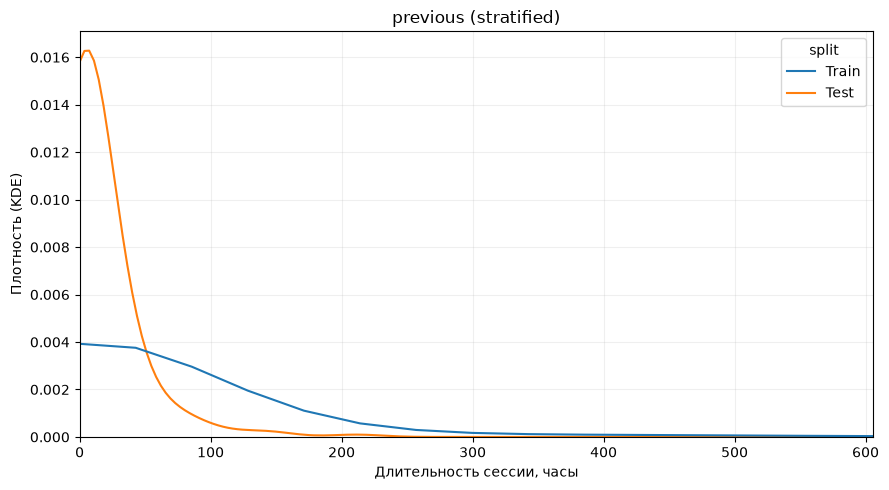

itplgn


,count,median,mean,share_over_100h
split,,,,
Test,438,25.33,124.96,27.17
Train,922,25.55,148.00,27.66


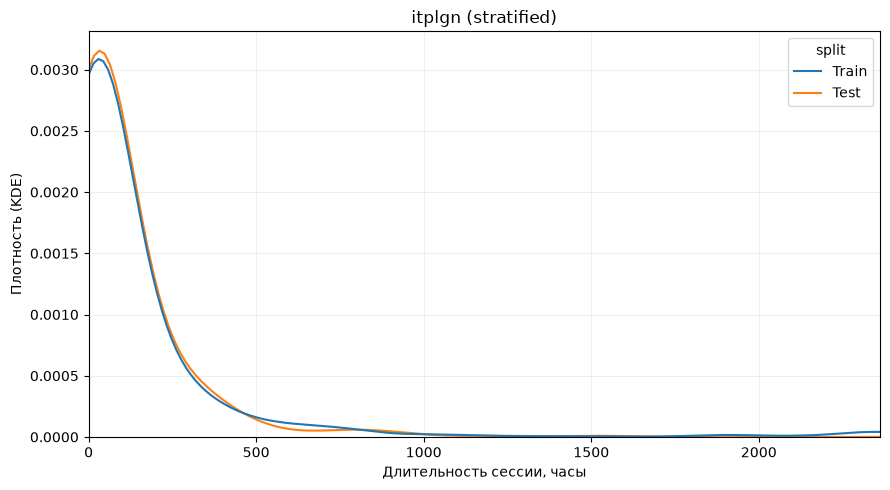

s-1547-3-410


,count,median,mean,share_over_100h
split,,,,
Test,584,6.33,42.40,8.56
Train,1403,6.29,43.34,8.55


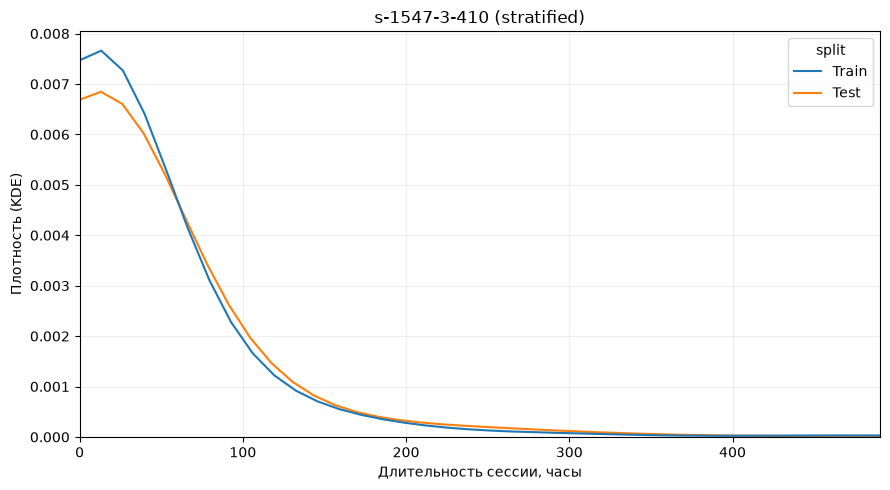

s-1547-3-413


,count,median,mean,share_over_100h
split,,,,
Test,438,6.11,40.81,6.16
Train,1095,6.32,45.96,9.04


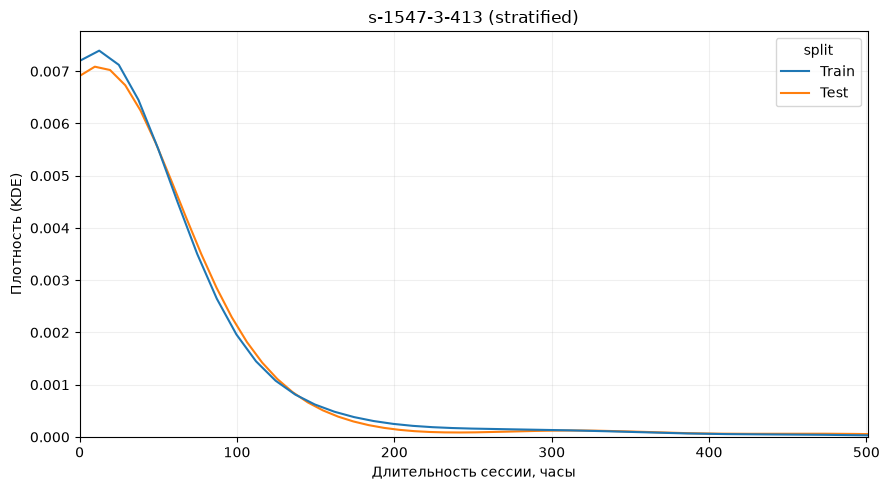

In [8]:
import seaborn as sns

def durations_for_split(machine_splits):
    train_machines = {m for g in GROUPS for m in machine_splits[g]["train"]}
    test_machines = {m for g in GROUPS for m in machine_splits[g]["test"]}
    assert train_machines.isdisjoint(test_machines)
    data = session_times[session_times["machine_id"].isin(train_machines | test_machines)].copy()
    data["split"] = np.where(data["machine_id"].isin(train_machines), "Train", "Test")
    return data

selected = durations_for_split(splits)

assert set(selected["case_id"]) == set(train["case_id"]) | set(test["case_id"])


def plot_duration_kde(data, title):
    print(title)
    table = data.groupby("split")["duration_hours"].agg(
        count="count", median="median", mean="mean",
        share_over_100h=lambda x: 100 * (x > 100).mean())
    display(table.round(2))
    xmax = data["duration_hours"].quantile(0.99)
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.kdeplot(data=data, x="duration_hours", hue="split",
                hue_order=["Train", "Test"], common_norm=False, cut=0, ax=ax)
    if xmax > 0:
        ax.set_xlim(0, xmax)
    ax.set_xlabel("Длительность сессии, часы")
    ax.set_ylabel("Плотность (KDE)")
    ax.set_title(title + " (" + SPLIT_MODE + ")")
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


for group in GROUPS:
    plot_duration_kde(selected[selected["group"] == group], group)


## 3. Построение сетей Петри

Используется алгоритм `pm4py.discover_petri_net_inductive`. Четыре групповые сети и одна общая обьединенная сеть (объединённые обучающие трассы). 

In [73]:
model_logs = {g: _to_event_log(train[train["group"] == g]) for g in GROUPS}
model_logs["all_groups"] = _to_event_log(train)
models = {}
rows = []
for name, pm_log in model_logs.items():
    start = time.perf_counter()
    net, im, fm = pm4py.discover_petri_net_inductive(pm_log)
    models[name] = (net, im, fm)
    rows.append({"model": name, "places": len(net.places),
                 "transitions": len(net.transitions), "arcs": len(net.arcs),
                 "build_seconds": round(time.perf_counter() - start, 2)})
display(pd.DataFrame(rows).set_index("model"))

,places,transitions,arcs,build_seconds
model,,,,
previous,27,42,90,2.89
itplgn,12,22,44,0.33
s-1547-3-410,9,14,28,0.07
s-1547-3-413,12,18,36,0.06
all_groups,18,34,70,4.00


## 4. Fitness и precision на своих и чужих группах

Строки - train, столбцы - test. 

Precision при `COMPUTE_PRECISION=True`. 

Значения на диагонали получены на не обучающих машинах.

In [74]:
fitness_logs = {g: _to_event_log(test_logs[g]) for g in GROUPS}
precision_logs = ({g: _to_event_log(sample_sessions(test_logs[g],
                   MAX_PRECISION_SESSIONS, SEED + 1)) for g in GROUPS}
                  if COMPUTE_PRECISION else {})
fitness = pd.DataFrame(index=list(models), columns=GROUPS, dtype=float)
precision = pd.DataFrame(index=list(models), columns=GROUPS, dtype=float)
for model_name, (net, im, fm) in models.items():
    for group in GROUPS:
        start = time.perf_counter()
        try:
            result = pm4py.fitness_token_based_replay(
                fitness_logs[group], net, im, fm)
            fitness.loc[model_name, group] = float(result["log_fitness"])
        except Exception as exc:
            print("Ошибка fitness:", model_name, group, repr(exc))
        print(f"{model_name} → {group}: fitness {fitness.loc[model_name, group]:.3f}, "
              f"{time.perf_counter()-start:.1f} с")
print("Fitness на тестовых машинах:")
display(fitness.round(3))

previous → previous: fitness 1.000, 0.9 с
previous → itplgn: fitness 1.000, 0.2 с
previous → s-1547-3-410: fitness 1.000, 0.2 с
previous → s-1547-3-413: fitness 0.990, 0.1 с
itplgn → previous: fitness 0.893, 3.8 с
itplgn → itplgn: fitness 1.000, 0.1 с
itplgn → s-1547-3-410: fitness 0.995, 0.1 с
itplgn → s-1547-3-413: fitness 0.985, 0.0 с
s-1547-3-410 → previous: fitness 0.803, 4.2 с
s-1547-3-410 → itplgn: fitness 1.000, 0.1 с
s-1547-3-410 → s-1547-3-410: fitness 1.000, 0.1 с
s-1547-3-410 → s-1547-3-413: fitness 1.000, 0.0 с
s-1547-3-413 → previous: fitness 0.982, 3.9 с
s-1547-3-413 → itplgn: fitness 1.000, 0.1 с
s-1547-3-413 → s-1547-3-410: fitness 1.000, 0.1 с
s-1547-3-413 → s-1547-3-413: fitness 1.000, 0.0 с
all_groups → previous: fitness 1.000, 0.4 с
all_groups → itplgn: fitness 1.000, 0.2 с
all_groups → s-1547-3-410: fitness 1.000, 0.1 с
all_groups → s-1547-3-413: fitness 1.000, 0.1 с
Fitness на тестовых машинах:


,previous,itplgn,s-1547-3-410,s-1547-3-413
previous,1.000,1.0,1.000,0.990
itplgn,0.893,1.0,0.995,0.985
s-1547-3-410,0.803,1.0,1.000,1.000
s-1547-3-413,0.982,1.0,1.000,1.000
all_groups,1.000,1.0,1.000,1.000


## 5. Precision
Обычно расчет долгий, выполняется при `COMPUTE_PRECISION=True` в первой ячейке.

In [75]:
if COMPUTE_PRECISION:
    for model_name, (net, im, fm) in models.items():
        for group in GROUPS:
            start = time.perf_counter()
            try:
                precision.loc[model_name, group] = float(
                    pm4py.precision_token_based_replay(
                        precision_logs[group], net, im, fm))
            except Exception as exc:
                print("Ошибка precision:", model_name, group, repr(exc))
            print(f"{model_name} → {group}: precision "
                  f"{precision.loc[model_name, group]:.3f}; "
                  f"{time.perf_counter()-start:.1f} с")
    display(precision.round(3))
else:
    print("Precision отключён.")

previous → previous: precision 0.112; 124.7 с
previous → itplgn: precision 0.170; 2.0 с
previous → s-1547-3-410: precision 0.158; 2.9 с
previous → s-1547-3-413: precision 0.198; 0.2 с
itplgn → previous: precision 0.358; 5.4 с
itplgn → itplgn: precision 0.220; 0.9 с
itplgn → s-1547-3-410: precision 0.225; 1.3 с
itplgn → s-1547-3-413: precision 0.335; 0.1 с
s-1547-3-410 → previous: precision 0.389; 22.9 с
s-1547-3-410 → itplgn: precision 0.336; 0.7 с
s-1547-3-410 → s-1547-3-410: precision 0.445; 1.0 с
s-1547-3-410 → s-1547-3-413: precision 0.504; 0.1 с
s-1547-3-413 → previous: precision 0.166; 22.7 с
s-1547-3-413 → itplgn: precision 0.399; 1.3 с
s-1547-3-413 → s-1547-3-410: precision 0.495; 1.2 с
s-1547-3-413 → s-1547-3-413: precision 0.559; 0.1 с
all_groups → previous: precision 0.107; 77.7 с
all_groups → itplgn: precision 0.128; 1.8 с
all_groups → s-1547-3-410: precision 0.121; 2.3 с
all_groups → s-1547-3-413: precision 0.152; 0.2 с


,previous,itplgn,s-1547-3-410,s-1547-3-413
previous,0.112,0.170,0.158,0.198
itplgn,0.358,0.220,0.225,0.335
s-1547-3-410,0.389,0.336,0.445,0.504
s-1547-3-413,0.166,0.399,0.495,0.559
all_groups,0.107,0.128,0.121,0.152


## 6. Сравнение вероятностей наблюдаемых переходов

Используем функцию `transition_table`. Сравниваем по каждой группе наиболее частые переходы и их вероятности.

In [76]:
tables = {g: transition_table(train[train["group"] == g]) for g in GROUPS}
counts = pd.concat([
    t.assign(group=g)[["group", "src", "dst", "count", "prob"]]
    for g, t in tables.items()
], ignore_index=True)
top = (counts.groupby(["src", "dst"])["count"].sum()
       .nlargest(15).index)
comparison = counts.pivot_table(
    index=["src", "dst"], columns="group", values="prob"
).reindex(top).reindex(columns=GROUPS).fillna(0)
print("Вероятности 15 наиболее частых переходов (по обучающим данным):")
display(comparison.round(3))

Вероятности 15 наиболее частых переходов (по обучающим данным):


group               previous  itplgn  s-1547-3-410  s-1547-3-413
src   dst                                                       
42    107              1.000   0.996         1.000         1.000
187   42               0.677   0.998         0.999         1.000
566   506              0.425   0.000         0.000         0.000
507   566              1.000   0.000         0.000         0.000
START 172              0.860   1.000         1.000         1.000
506   566              0.777   0.000         0.000         0.000
107   187              0.148   0.405         0.364         0.373
      131              0.416   0.357         0.254         0.203
131   130              0.961   1.000         1.000         1.000
566   507              0.200   0.000         0.000         0.000
109   END_CENSORED     0.885   0.983         0.982         0.903
566   566              0.176   0.000         0.000         0.000
130   42               0.892   0.567         0.227         0.258
172   109              0.098   0.002         0.307         0.394
      521              0.049   0.925         0.000         0.000

## 7. Матрицы качества и вывод

Высокий fitness означает, что сеть воспроизводит наблюдаемые трассы. Низкий precision означает, что сеть допускает слишком много лишних последовательностей.

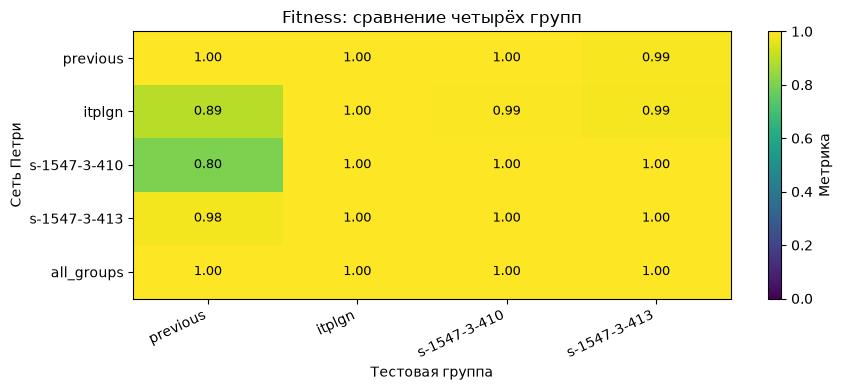

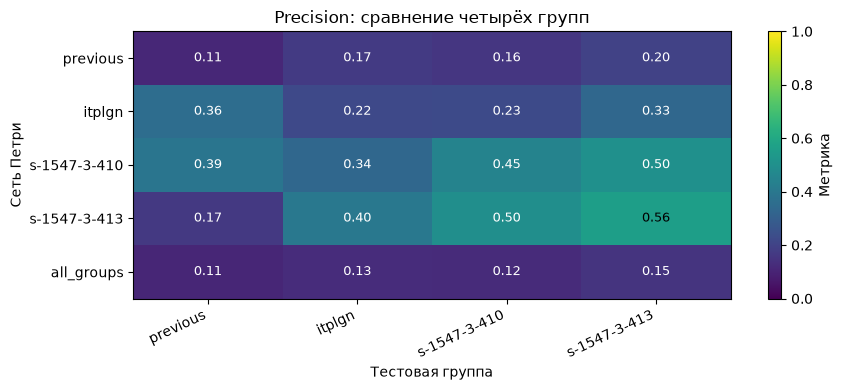

In [77]:
def show_matrix(values, title):
    fig, ax = plt.subplots(figsize=(9, 4))
    arr = values.to_numpy(dtype=float)
    image = ax.imshow(arr, vmin=0, vmax=1, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(values.columns)), values.columns, rotation=25, ha="right")
    ax.set_yticks(range(len(values.index)), values.index)
    ax.set_xlabel("Тестовая группа")
    ax.set_ylabel("Сеть Петри")
    ax.set_title(title)
    for i in range(len(values.index)):
        for j in range(len(values.columns)):
            if np.isfinite(arr[i, j]):
                ax.text(j, i, f"{arr[i,j]:.2f}", ha="center", va="center",
                        color="white" if arr[i,j] < 0.55 else "black", fontsize=9)
    fig.colorbar(image, ax=ax, label="Метрика")
    plt.tight_layout()
    plt.show()

show_matrix(fitness, "Fitness: сравнение четырёх групп")
if COMPUTE_PRECISION:
    show_matrix(precision, "Precision: сравнение четырёх групп")


## 8. Сети Петри и графы переходов как в ноутбуке 05

Искользуется функции `state_petri_net`, `draw_state_net` и `state_graph` из `src/censored_petri.py`, что и в ноутбуке 05, но без подбора распределений времени. На схемах показаны наблюдаемые частоты переходов и цензура.

- `VISUALIZE_TARGETS`: список групп или машин. `GROUPS` - четыре отдельные группы, `GROUPS + ["all_groups"]` - они же и ещё одна общая схема, `["all_groups"]` - только общая схема.
- `VISUALIZE_SCOPE = "all"`: все доступные сессии выбранных групп (включая тестовые и машины ниже порога). 
- `VISUALIZE_SCOPE = "train"`: только обучающие машины, как в разделе 3.
- `VISUALIZE_STYLE`: `"petri"` - сеть состояний, `"graph"` - граф наблюдаемых переходов, `"both"` - оба рисунка.


all_groups | all: машин 81, сессий 6013, цензурировано 2871


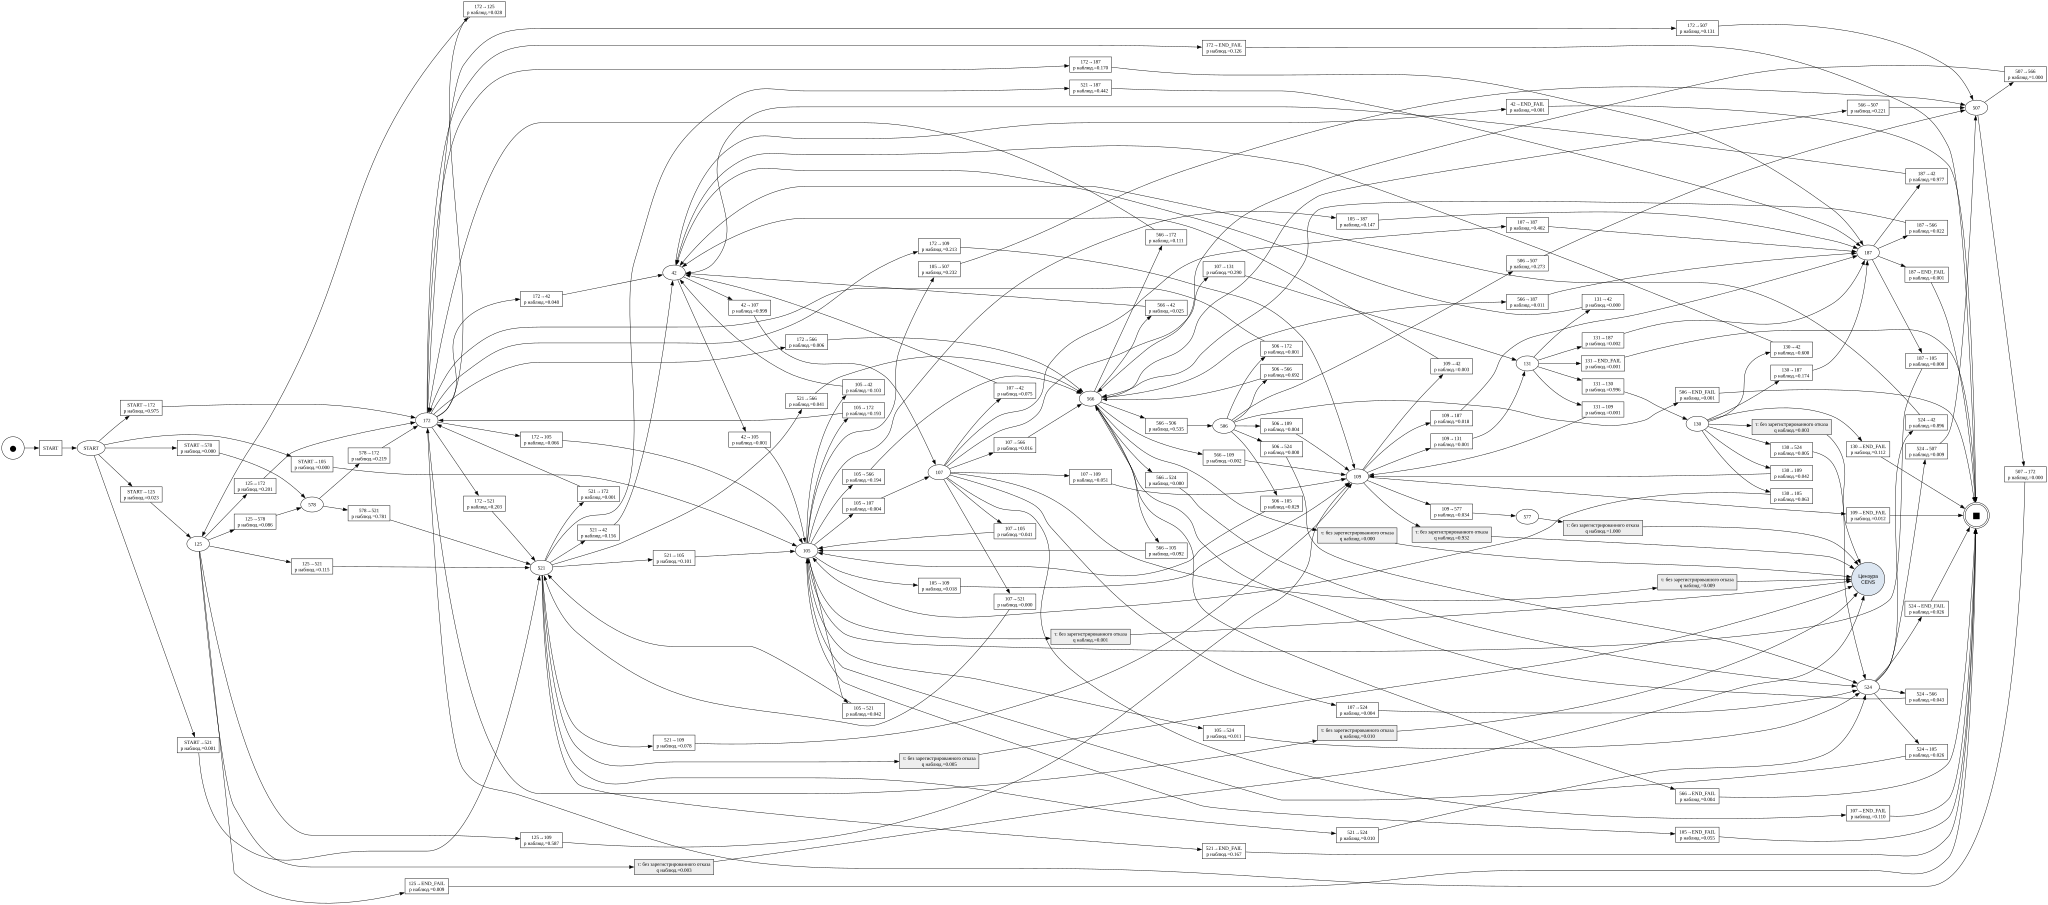

Сохранено в: c:\Users\lena\Desktop\diplom\EquipmentEventLogGeneration\results\petri_nets\kernel_power\clusters


In [78]:
from src.cluster_comparison import component_intervals_for_visualization
from src import censored_petri as cp
import shutil

VISUALIZE_TARGETS = ["all_groups"]     # или ["all_groups"], или GROUPS + ["all_groups"]
VISUALIZE_SCOPE = "all"                    # "all" - все данные, "train" - только обучающие машины
VISUALIZE_STYLE = "petri"                  # "petri", "graph", "both"
SHOW_CENSORED_EXAMPLE = False              # пример фишки в CENS
SAVE_VISUALIZATION = True                 # сохранение SVG только при True

if VISUALIZE_SCOPE not in ("all", "train"):
    raise ValueError('VISUALIZE_SCOPE должен быть "all" или "train"')
if VISUALIZE_STYLE not in ("petri", "graph", "both"):
    raise ValueError('VISUALIZE_STYLE: "petri", "graph" или "both"')
if isinstance(VISUALIZE_TARGETS, str):
    VISUALIZE_TARGETS = [VISUALIZE_TARGETS]

chosen_log = log if VISUALIZE_SCOPE == "all" else train
visual_intervals = component_intervals_for_visualization(chosen_log, sessions)
available_machines = set(chosen_log["machine_id"])
if shutil.which("dot") is None:
    print("Graphviz (dot) не найден в PATH. Для отображения SVG нужен установленный Graphviz.")
else:
    for target in VISUALIZE_TARGETS:
        if target == "all_groups":
            part = visual_intervals
        elif target in GROUPS:
            part = visual_intervals.loc[visual_intervals["group"] == target]
        elif target in available_machines:
            part = visual_intervals.loc[visual_intervals["machine_id"] == target]
        else:
            raise ValueError(f"Неизвестная группа/машина: {target}. Список машин: stats['machine_id']")
        if part.empty:
            raise ValueError(f"Нет интервалов для {target} в режиме {VISUALIZE_SCOPE}")

        n_cases = part["case_id"].nunique()
        n_machines = part["machine_id"].nunique()
        n_censored = part.loc[~part["observed"], "case_id"].nunique()
        print(f"{target} | {VISUALIZE_SCOPE}: машин {n_machines}, "
              f"сессий {n_cases}, цензурировано {n_censored}")

        if SAVE_VISUALIZATION:
            folder = root / "results" / "petri_nets" / "kernel_power" / "clusters"
            folder.mkdir(parents=True, exist_ok=True)
            filename = f"{target.replace(':', '_')}_{VISUALIZE_SCOPE}"
            if VISUALIZE_SCOPE == "train" and SPLIT_MODE == "stratified":
                filename += "_stratified"

        if VISUALIZE_STYLE in ("petri", "both"):
            net, im, fm = cp.state_petri_net(
                part, start="START", terminal="END_FAIL", estimates=None)
            decorations = cp.state_net_decorations(
                net, {"censored": "без зарегистрированного отказа"})
            for tr in net.transitions:
                if tr.name != "start" and not tr.properties.get("censor_reason"):
                    p = tr.properties["observed_probability"]
                    decorations[tr]["label"] = f"{tr.name}\np наблюд.={p:.3f}"

            marking = im
            if SHOW_CENSORED_EXAMPLE:
                cases = part.loc[~part["observed"], "case_id"].drop_duplicates()
                if len(cases):
                    path = part.loc[part["case_id"] == cases.iloc[0]]
                    states = [*path.loc[path["observed"], "src"].tolist(),
                              path["src"].iloc[-1]]
                    marking = cp.replay_censored(net, im, states, reason="censored")
                    print(f"Пример цензурированной сессии: {cases.iloc[0]}")
            picture = cp.draw_state_net(
                net, marking, fm, decorations=decorations,
                reason_labels={"censored": "без зарегистрированного отказа"})
            display(picture)
            if SAVE_VISUALIZATION:
                picture.render(filename=filename + "_petri", directory=str(folder),
                               format="svg", cleanup=True)

        if VISUALIZE_STYLE in ("graph", "both"):
            picture = cp.state_graph(
                part, start="START", terminal="END_FAIL",
                title=f"{target}: наблюдаемые переходы ({VISUALIZE_SCOPE})",
                reason_labels={"censored": "без зарегистрированного отказа"})
            display(picture)
            if SAVE_VISUALIZATION:
                picture.render(filename=filename + "_graph", directory=str(folder),
                               format="svg", cleanup=True)

        if SAVE_VISUALIZATION:
            print("Сохранено в:", folder)